# Passau MedCo · Logistic Regression Reference

> **Not the final model.** This notebook was our first Task 2 model. The team later chose **XGBoost** as the final model ([02_modeling.ipynb](02_modeling.ipynb)). A logistic regression can already be read from its coefficients, so LIME would add little. Its ranking quality is at least as good as XGBoost's (test AP 0.66 here vs. 0.60 for XGBoost on the same test employees). The notebook therefore remains as an interpretable reference.

**Can we use a model to reliably predict employee attrition?**

Train a regularized logistic regression on the fictional IBM HR data and evaluate how well it ranks and flags employees who left.

## 1. Why logistic regression?

Each employee has one binary outcome. Logistic regression adds feature contributions on the log-odds scale and produces a score that ranks employees by estimated attrition risk. Coefficients can later be inspected. In the earlier [model comparison](model_comparison.ipynb), logistic regression ranked employees ahead of random forest and histogram gradient boosting. **Average precision (AP)** summarizes precision across the recall curve. A constant score has AP equal to the exit share, around 16% here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    cross_val_predict,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PowerTransformer, StandardScaler

## 2. Who is available for training?

Keep the original stratified 80/20 split (seed 42). Stratification preserves the minority class, and 20% leaves 47 exits for the final report. Employee IDs check that each person appears once. The target, ID and three source constants are excluded from the inputs.

**Prediction time.** Imagine scoring active employees on an HR reporting date. Tenure, overtime, survey responses, the latest pay increase and performance review must all refer to information recorded by that date. An exit interview or a raise recorded later would leak future information. The CSV contains neither measurement dates nor exit dates. It supports a snapshot classification exercise with no verifiable forecast horizon. The project EDA describes the full snapshot and this historical test set has been reported before.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
# The CSV pads some headers and text values with spaces. Clean both before using labels such as "Yes".
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip().replace("", pd.NA)

random_seed = 42
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].notna().all() and employees["EmployeeNumber"].is_unique
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

# X holds the features. The employee ID was useful for checking uniqueness, and Attrition is the label.
# These three fields are constants in the source schema. Check on training rows below.
constant_columns = ["EmployeeCount", "Over18", "StandardHours"]
X = employees.drop(columns=["EmployeeNumber", "Attrition", *constant_columns])
y = employees["Attrition"].eq("Yes").astype(int)

# Stratification keeps the share of employees who left similar in both partitions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=random_seed
)
assert employees.loc[X_train.index, constant_columns].nunique(dropna=False).eq(1).all()
assert not X_train.isna().any().any(), "Review missing inputs before fitting."
print(f"Training: {len(y_train):,} employees, {y_train.sum()} exits ({y_train.mean():.1%}).")

Training: 1,176 employees, 190 exits (16.2%).


## 3. What does the model learn?

Text categories, job level, stock option level and work-life balance get separate one-hot indicators. For the other ordered scales (education, involvement and the three satisfaction measures), one step has a constant effect on log-odds. That is a simplifying assumption. Performance rating has only two observed values, 3 and 4. Its coefficient can represent the step at a 20% pay increase alongside the numeric pay rise.

Scaling gives numeric inputs comparable units for the **L2 penalty**, which shrinks large coefficients. Smaller `C` means stronger shrinkage. The four inner folds choose `C` and either standard scaling or a Yeo–Johnson transform for income and the two skewed tenure/experience measures. Each fit learns its own scales, categories, transforms and income medians by job level. The solver uses L2 with equal class weights.

We test two single additions motivated by the training-only age and manager-tenure tables in the EDA: curvature in the age effect and a separate indicator for zero completed years with the current manager. Both keep their original numeric feature. Earlier training CV found no stable gain from removing performance rating or adding overtime interactions; these remain documented in the EDA.

In [3]:
class IncomeWithinJobLevel(TransformerMixin, BaseEstimator):
    """Compare monthly income with the median for the employee's job level."""

    def fit(self, X, y=None):
        # This runs inside the pipeline, so the medians come from the current training fold.
        self.level_medians_ = X.groupby("JobLevel")["MonthlyIncome"].median()
        self.overall_median_ = X["MonthlyIncome"].median()
        return self

    def transform(self, X):
        # A ratio of 1.0 means income equals the median for that job level.
        # Use the training-wide median if prediction data contains a new job level.
        level_median = X["JobLevel"].map(self.level_medians_).fillna(self.overall_median_)
        return (X["MonthlyIncome"] / level_median).to_frame("MonthlyIncomeRelativeToJobLevel")

    def get_feature_names_out(self, input_features=None):
        return ["MonthlyIncomeRelativeToJobLevel"]


categorical_features = X_train.select_dtypes(include="str").columns.tolist()
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
skewed_features = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
# EDA showed uneven attrition rates across these codes. One-hot encoding lets the model learn
# a separate effect for each level.
categorical_levels = ["JobLevel", "StockOptionLevel", "WorkLifeBalance"]

# PerformanceRating marks the 20% salary-increase cutoff in this dataset. The rating can
# represent a step at that cutoff alongside the numeric PercentSalaryHike feature.
linear_numeric = [
    column for column in numeric_features
    if column not in skewed_features and column not in categorical_levels
]
# Scaling makes regularization comparable across numeric features measured in different units.
# The search also tests a power transform for the three skewed numeric features.


def age_curvature(frame):
    # Alongside linear age, one squared term allows the slope to change with age.
    return (frame[["Age"]] - 40).pow(2)


def zero_manager_years(frame):
    # Zero completed years may describe a new hire or a change of manager.
    return frame[["YearsWithCurrManager"]].eq(0).astype(int)


def make_search(extra_term=None):
    blocks = [
        ("numeric", StandardScaler(), linear_numeric),
        ("skewed", StandardScaler(), skewed_features),
        ("relative_income", make_pipeline(IncomeWithinJobLevel(), StandardScaler()), ["JobLevel", "MonthlyIncome"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), [*categorical_features, *categorical_levels]),
    ]
    if extra_term is not None:
        blocks.append(extra_term)
    model = make_pipeline(ColumnTransformer(blocks), LogisticRegression(max_iter=1000))
    return GridSearchCV(
        model,
        {"logisticregression__C": [0.03, 0.1, 0.3, 1.0, 3.0],
         "columntransformer__skewed": [StandardScaler(), PowerTransformer()]},
        scoring="average_precision", cv=inner_cv, error_score="raise",
    )


inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
variants = {
    "Current": None,
    "Curved age": ("age_squared", make_pipeline(FunctionTransformer(age_curvature), StandardScaler()), ["Age"]),
    "Zero manager years": ("manager_zero", FunctionTransformer(zero_manager_years), ["YearsWithCurrManager"]),
}

### How is the alert threshold chosen?

In each outer training fold, choose the settings with the highest mean inner AP. With those settings, produce four-fold out-of-fold scores for that same training pool. Choose the threshold with the **highest precision among cutoffs reaching at least 70% recall** on those scores; ties favor higher recall. We also keep the cutoff maximizing F1 for comparison with the earlier report. Lock both cutoffs before scoring the outer validation employees. A threshold targeting 70% recall can miss that target on new data.

In [4]:
def choose_cutoffs(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    precision, recall = precision[:-1], recall[:-1]  # last point has no cutoff
    f1 = 2 * precision * recall / (precision + recall).clip(min=1e-12)
    eligible = recall >= 0.70
    return {
        "Recall target": thresholds[eligible][precision[eligible].argmax()],
        "F1": thresholds[f1.argmax()],
    }


def fit_and_choose(name, features, labels):
    search = make_search(variants[name]).fit(features, labels)
    inner_scores = cross_val_predict(
        search.best_estimator_, features, labels, cv=inner_cv, method="predict_proba"
    )[:, 1]
    return search, choose_cutoffs(labels, inner_scores)

### Which changes survive different partitions?

Run the current pipeline first to reproduce the earlier mean CV-AP of 0.688. Reuse its five outer folds for each alternative in each of three shuffles (seeds 19, 83 and 137). Each employee is validated once per shuffle. We report the spread across the 15 folds; overlapping training sets make this a descriptive spread.

To keep a change, require higher mean AP in **each** shuffle, at least the baseline mean precision at the locked recall-target cutoff, and at least as many folds actually reaching 70% recall. Among qualifying changes choose the highest mean AP. The test set takes no part in this rule.

In [5]:
seeds = (19, 83, 137)
outer_folds = {
    seed: list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X_train, y_train))
    for seed in seeds
}
rows = []
historical_scores = pd.Series(index=X_train.index, dtype=float)

# Single-threaded numerical fits avoid oversubscribing small training folds.
with threadpool_limits(limits=1):
    for name in variants:
        for seed, folds in outer_folds.items():
            for fold, (fit, valid) in enumerate(folds, start=1):
                search, cutoffs = fit_and_choose(name, X_train.iloc[fit], y_train.iloc[fit])
                labels = y_train.iloc[valid]
                scores = search.predict_proba(X_train.iloc[valid])[:, 1]
                alerts = scores >= cutoffs["Recall target"]
                rows.append({
                    "Variant": name, "Seed": seed, "Fold": fold,
                    "AP": average_precision_score(labels, scores),
                    "Precision": precision_score(labels, alerts, zero_division=0),
                    "Recall": recall_score(labels, alerts),
                })
                # The original report chose its F1 cutoff from this first shuffle.
                if name == "Current" and seed == seeds[0]:
                    historical_scores.iloc[valid] = scores
        if name == "Current":
            baseline_ap = pd.DataFrame(rows)["AP"].mean()
            print(f"Reproduced baseline CV-AP: {baseline_ap:.3f} (previously 0.688)")

fold_results = pd.DataFrame(rows)
fold_results["Reached 70%"] = fold_results["Recall"].ge(0.70)
by_shuffle = fold_results.pivot_table(index="Variant", columns="Seed", values="AP")
display(by_shuffle.round(3))

Reproduced baseline CV-AP: 0.688 (previously 0.688)


Seed,19,83,137
Variant,,,
Current,0.699,0.680,0.686
Curved age,0.688,0.671,0.686
Zero manager years,0.701,0.692,0.698


In [6]:
groups = fold_results.groupby("Variant", sort=False)
summary = groups.agg(
    AP=("AP", "mean"), Precision=("Precision", "mean"), Recall=("Recall", "mean"),
    Folds_at_target=("Reached 70%", "sum"),
)
spread = groups[["AP", "Precision", "Recall"]].std().add_suffix(" SD")
# Conditional precision uses only folds that actually reached the recall target.
at_target = fold_results.loc[fold_results["Reached 70%"]].groupby("Variant")["Precision"].mean()
display(summary.join(spread).assign(Precision_when_reached=at_target).round(3))

baseline = summary.loc["Current"]
eligible = (
    by_shuffle.gt(by_shuffle.loc["Current"]).all(axis=1)
    & summary["Precision"].ge(baseline["Precision"])
    & summary["Folds_at_target"].ge(baseline["Folds_at_target"])
)
selected = summary.loc[eligible, "AP"].idxmax() if eligible.any() else "Current"
print("Selected for final fit:", selected)

,AP,Precision,Recall,Folds_at_target,AP SD,Precision SD,Recall SD,Precision_when_reached
Variant,,,,,,,,
Current,0.688,0.495,0.711,9,0.051,0.052,0.077,0.490
Curved age,0.682,0.502,0.700,8,0.053,0.049,0.092,0.481
Zero manager years,0.697,0.509,0.702,10,0.061,0.065,0.104,0.501


Selected for final fit: Zero manager years


**Decision from training data.** Adding zero completed manager years raised mean AP from 0.688 to 0.697 and improved the mean in each shuffle. At the locked recall-target threshold, average precision among flagged employees rose from 49.5% to 50.9%; mean recall moved from 71.1% to 70.2%. The new rule reached its target in 10 of 15 validation folds. Recall varied by about 10 percentage points across folds (standard deviation). The curved age term lowered mean AP to 0.682. We keep only the manager indicator.

## 4. What does the chosen rule achieve on the historical test set?

Repeat the four-fold search and threshold choice on all 1,176 training employees. The primary rule targets recall because missing exits matters for this exercise. F1 gives equal weight to precision and recall. For a like-for-like comparison, also show the current pipeline under the same two rules and reconstruct its historical F1 cutoff from the first shuffle. Evaluate all locked decisions on the same 294 test employees.

In [7]:
with threadpool_limits(limits=1):
    final_fits = {
        name: fit_and_choose(name, X_train, y_train)
        for name in dict.fromkeys(["Current", selected])
    }
historical_f1 = choose_cutoffs(y_train, historical_scores)["F1"]
test_rows = []
for name, (search, cutoffs) in final_fits.items():
    scores = search.predict_proba(X_test)[:, 1]
    rules = {"Historical F1": historical_f1, **cutoffs} if name == "Current" else cutoffs
    for rule, cutoff in rules.items():
        alerts = scores >= cutoff
        test_rows.append({
            "Variant": name, "Rule": rule, "Cutoff": cutoff,
            "AP": average_precision_score(y_test, scores),
            "Precision": precision_score(y_test, alerts, zero_division=0),
            "Recall": recall_score(y_test, alerts), "F1": f1_score(y_test, alerts),
            "Detected": int(y_test[alerts].sum()), "False alarms": int((1 - y_test[alerts]).sum()),
        })
        if name == selected and rule == "Recall target":
            selected_alerts = alerts
test_results = pd.DataFrame(test_rows).set_index(["Variant", "Rule"])
display(test_results.round(3))
print("Final settings:", final_fits[selected][0].best_params_)
print(f"Test employees: {len(y_test)}; exits: {y_test.sum()}; constant-score AP: {y_test.mean():.3f}")

Cutoff     AP  Precision  Recall     F1  \
Variant            Rule                                                     
Current            Historical F1   0.431  0.672      0.781   0.532  0.633   
                   Recall target   0.276  0.672      0.542   0.681  0.604   
                   F1              0.364  0.672      0.614   0.574  0.593   
Zero manager years Recall target   0.253  0.661      0.532   0.702  0.606   
                   F1              0.324  0.661      0.560   0.596  0.577   

                                  Detected  False alarms  
Variant            Rule                                   
Current            Historical F1        25             7  
                   Recall target        32            27  
                   F1                   27            17  
Zero manager years Recall target        33            29  
                   F1                   28            22

Final settings: {'columntransformer__skewed': PowerTransformer(), 'logisticregression__C': 0.3}
Test employees: 294; exits: 47; constant-score AP: 0.160


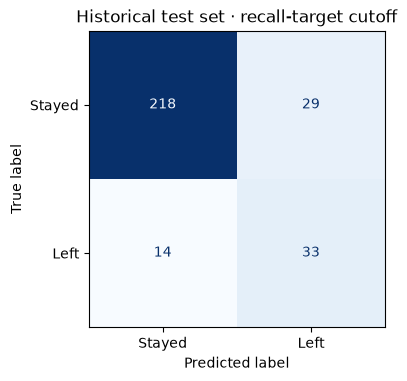

In [8]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(4.5, 3.7), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, selected_alerts, labels=[0, 1], display_labels=["Stayed", "Left"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Historical test set · recall-target cutoff")
plt.show()

### What can Passau MedCo conclude?

The historical baseline reproduces **AP 0.672, 25/47 detected exits and 7 false alarms** at its original F1 cutoff. Under the same new recall-target rule, the baseline detected 32 exits with 27 false alarms. The selected model (L2, `C = 0.3`, Yeo–Johnson) detected **33 of 47** with **29 false alarms**. That gives 53.2% precision, 70.2% recall and F1 of 0.606. The matrix also shows 14 missed exits and 218 correctly classified employees who stayed.

The selected model improved cross-validated ranking, while test AP fell to **0.661**. Most of the increase in detected exits over the historical F1 result comes from the threshold policy. The score can help identify a group with elevated attrition in this snapshot. Reliability for individual predictions at a future date still requires a new, dated cohort, features recorded before each prediction, and a decision on the costs of false alerts and missed exits.